# Sujet 3 expliqué depuis zéro · gradient simple et recuit simulé

Version « cours » du notebook de rendu [s3_1_recuit_simule.ipynb](s3_1_recuit_simule.ipynb) :
mêmes calculs, **même graine (2026), même ordre de tirages**, donc les mêmes chiffres, mais tout
est repris depuis le début pour que tu puisses le **réexpliquer au jury**.

**Mode d'emploi.** Lis dans l'ordre, exécute chaque cellule (*Run All* fonctionne), fais les
exercices ✋ avant d'ouvrir les corrigés, puis entraîne-toi à dire les blocs 🗣️ à voix haute.

| Symbole | Bloc | Contenu |
|---|---|---|
| 🎯 | Objectif | ce qu'on demande vraiment |
| 💡 | Intuition | l'idée en une phrase + une figure |
| 🧮 | Calcul | les étapes, chacune justifiée |
| 🐍 | Code | la vraie fonction de `src/stats_td/`, expliquée |
| 📊 | Lecture | ce que disent les chiffres réels |
| ⚠️ | Pièges | erreurs classiques, coquilles |
| ✋ | À toi | exercice + corrigé replié |
| 🗣️ | 30 s | la réponse à dire au jury |
| 🎤 | Jury | questions probables ([questions_oral.md](questions_oral.md)) |

**Plan.** Préparation · Partie 0 (les bases) · Q1 la fonction $h$ · Q2 gradient · Q3 recuit ·
Q4 comparaison · Récap.

## Préparation

La cellule suivante charge les outils. Ligne par ligne :
- `sys.path.insert(...)` : dit à Python où trouver notre code (`src/stats_td/`) ;
- `inspect` : permet d'afficher le code source d'une fonction (blocs 🐍) ;
- `style()` : réglages communs des figures ;
- `rng = np.random.default_rng(GRAINE)` : **le** générateur aléatoire, graine 2026. Tous les
  tirages passent par lui, dans le même ordre que le notebook de rendu.

In [1]:
import inspect, sys
from pathlib import Path
sys.path.insert(0, str(Path("../../src").resolve()))   # pour importer stats_td

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq                     # zéro d'une fonction sur un intervalle
from stats_td.figures import style, VIOLET, ROUGE, GRIS
from stats_td.optimisation import (BORNES_SUJET3, h_sujet3, dh_sujet3, pas_sujet3,
                                   gradient_simple, recuit_simule, minima_locaux)

style()
GRAINE = 2026
rng = np.random.default_rng(GRAINE)   # même graine que le notebook de rendu
a, b = BORNES_SUJET3                   # a = -8π, b = 8π

## Partie 0 · Les bases

### 0.1 Optimiser, c'est chercher le point le plus bas
Imagine une **randonnée dans le brouillard** sur un terrain vallonné dont l'altitude au point $x$
est $h(x)$. Tu veux atteindre le **fond de vallée le plus bas**.
- Un **minimum local** : un creux, plus bas que tous ses voisins proches (une cuvette).
- Le **minimum global** : le creux le plus bas de tout le terrain.
- Le **bassin d'attraction** d'un minimum : l'ensemble des points d'où, en descendant toujours,
  on arrive à ce minimum. Ses bords sont les sommets (maxima locaux) qui l'entourent.

Notation : $x^\star$ = un point où $h$ atteint son minimum ; $\arg\min h$ = l'ensemble de ces points.
Maximiser $h$, c'est minimiser $-h$ : $\max h = -\min(-h)$, atteint aux mêmes points.

### 0.2 La dérivée = la pente
$h'(x)$ est la pente au point $x$. Si $h'(x) < 0$, le terrain descend vers la droite ; si
$h'(x) > 0$, il descend vers la gauche. Donc **aller dans le sens de $-h'(x)$, c'est descendre**.
En un minimum (ou un maximum), $h'(x) = 0$. La dérivée seconde $h''$ est la **courbure** :
$h'' > 0$ = cuvette, $h'' < 0$ = bosse.

Une fonction est **convexe** si $h'' \ge 0$ partout (une seule cuvette) : alors tout minimum local
est global. Sinon, plusieurs cuvettes peuvent coexister.

### 0.3 Déterministe ou stochastique
- **Déterministe** : mêmes données ⇒ même résultat (le gradient).
- **Stochastique** : utilise du hasard ⇒ le résultat change à chaque lancer (le recuit). Pour
  juger un algorithme stochastique, on le **relance beaucoup de fois** et on fait des
  statistiques (proportion de succès, erreur-type, intervalle de confiance).

### 0.4 Accepter « avec probabilité $p$ »
$U \sim \mathcal U[0,1]$ (lire « $U$ suit la loi uniforme sur $[0,1]$ ») vérifie $P(U < p) = p$
pour $p \in [0,1]$ : c'est sa fonction de répartition, vue au sujet 1. Donc « accepter avec
probabilité $p$ » se code : `if rng.random() < p`.

### 0.5 Chaîne de Markov (pour le recuit)
Une suite aléatoire $(x_n)$ est une **chaîne de Markov** si $x_{n+1}$ ne dépend du passé qu'à
travers $x_n$. Une loi $\mu$ est **stationnaire** si, quand $x_n \sim \mu$, alors
$x_{n+1} \sim \mu$ aussi : c'est l'état d'équilibre vers lequel la chaîne tend.

### 0.6 Erreur-type d'une proportion
Si on observe $k$ succès sur $R$ essais indépendants, $\hat p = k/R$ estime $p$ avec une
**erreur-type** $\sqrt{\hat p(1-\hat p)/R}$, et un intervalle de confiance à 95 % est
$\hat p \pm 1{,}96 \times$ erreur-type (TCL).

### 0.7 Outils Python ↔ Matlab
| Besoin | Matlab (énoncé) | Python |
|---|---|---|
| grille | `linspace(a,b,n)` | `np.linspace(a, b, n)` |
| boucle | `for n = 1:N` | `for n in range(1, N + 1):` |
| uniforme | `rand` | `rng.random()` |
| minimum + position | `[m,i] = min(h)` | `i = np.argmin(h)` |
| test | `if ... end` | `if ...:` |
| tracer, superposer | `plot`, `hold on` | `ax.plot(...)` deux fois sur le même `ax` |

### ✋ À toi (Partie 0)
1. Pour $h(x) = (x-1)^2$, calcule $h'(3)$. Dans quel sens faut-il bouger pour descendre ?
2. Simule 10 000 tirages « pile avec probabilité 0,3 » avec `rng_exo` et vérifie la fréquence.
   (On utilise un générateur **à part**, `rng_exo`, pour ne pas décaler les tirages de `rng`.)

In [2]:
rng_exo = np.random.default_rng(0)   # générateur réservé aux exercices
# 1. h'(x) = ... ; h'(3) = ...
# 2. tirages = rng_exo.random(10_000) < 0.3 ; print(tirages.mean())

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

1. $h'(x) = 2(x-1)$, $h'(3) = 4 > 0$ : la pente monte vers la droite, donc on descend en allant
   vers la **gauche** (sens de $-h'$), vers $x^\star = 1$.
2. ```python
   tirages = rng_exo.random(10_000) < 0.3
   print(tirages.mean())   # ≈ 0,3 ; écart typique sqrt(0,3·0,7/10000) ≈ 0,005
   ```

</details>

---
## Q1 · Représenter $h$ sur $[-8\pi, 8\pi]$

### 🎯 Objectif
*Énoncé :* « Représenter la fonction $h(x)$ sur l'intervalle $[-8\pi, +8\pi]$ [en discrétisant sur
5000 points]. Remarquer que $h$ présente un certain nombre d'extrema locaux non globaux vers
lesquels l'algorithme du gradient simple est susceptible de converger. »

**Ce qu'on demande vraiment :** tracer la courbe (calculer $h$ en 5000 points régulièrement
espacés et les relier), **compter les creux**, repérer le plus bas, et situer le départ
$x_0 = 7{,}5$. Extremum = minimum ou maximum.

### 💡 Intuition
$h(x) = x^2 + 3x\cos x$ = une **parabole** ($x^2$) + une **vague** ($3x\cos x$) dont la hauteur
$3|x|$ grandit. La vague creuse des cuvettes dans la parabole : beaucoup de minima locaux. Mais
comme $3x\cos x$ reste entre $-3|x|$ et $3|x|$, la courbe est coincée entre $x^2 - 3|x|$ et
$x^2 + 3|x|$ (figure).

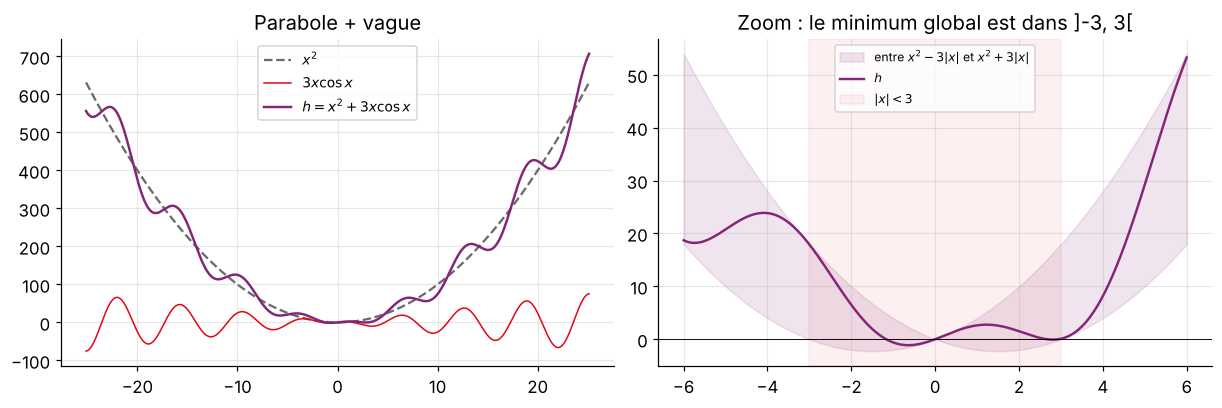

In [3]:
y = np.linspace(a, b, 5000)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
ax1.plot(y, y**2, color=GRIS, ls="--", label=r"$x^2$")
ax1.plot(y, 3 * y * np.cos(y), color=ROUGE, lw=1, label=r"$3x\cos x$")
ax1.plot(y, h_sujet3(y), color=VIOLET, lw=1.6, label=r"$h = x^2 + 3x\cos x$")
ax1.set_title("Parabole + vague"); ax1.legend(fontsize=9)
z = (y > -6) & (y < 6)
ax2.fill_between(y[z], y[z]**2 - 3 * np.abs(y[z]), y[z]**2 + 3 * np.abs(y[z]), color=VIOLET, alpha=0.12,
                 label=r"entre $x^2 - 3|x|$ et $x^2 + 3|x|$")
ax2.plot(y[z], h_sujet3(y[z]), color=VIOLET, lw=1.6, label=r"$h$")
ax2.axhline(0, color="k", lw=0.6); ax2.axvspan(-3, 3, color=ROUGE, alpha=0.06, label=r"$|x| < 3$")
ax2.set_title("Zoom : le minimum global est dans ]-3, 3["); ax2.legend(fontsize=8)
plt.show()

### 🧮 Calcul

| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1 | $(3x\cos x)' = 3\cos x - 3x\sin x$ | dérivée d'un produit $(uv)' = u'v + uv'$, $u = 3x$, $v = \cos x$ |
| 2 | $h'(x) = 2x + 3\cos x - 3x\sin x$ | linéarité de la dérivée |
| 3 | $h''(x) = 2 - 3\sin x - 3\sin x - 3x\cos x = 2 - 6\sin x - 3x\cos x$ | on redérive, produit pour $-3x\sin x$ |
| 4 | $-3x\cos x$ dépasse 2 en valeur absolue dès que $\lvert x\rvert$ n'est pas petit | $\cos x$ prend des valeurs proches de $\pm1$ sur chaque période |
| 5 | donc $h''$ change de signe : $h$ **non convexe** | définition de la convexité ($h'' \ge 0$ partout) |
| 6 | $3x\cos x \ge -3\lvert x\rvert$ | $\lvert\cos x\rvert \le 1$ |
| 7 | $h(x) \ge x^2 - 3\lvert x\rvert = \lvert x\rvert(\lvert x\rvert - 3)$ | on ajoute $x^2$ aux deux membres |
| 8 | $h(x) > 0$ si $\lvert x\rvert > 3$ | produit de deux nombres $> 0$ |
| 9 | $h(-0{,}637) \approx -1{,}130 < 0$ | calcul (ci-dessous) |

$$\boxed{\text{le minimum global de } h \text{ est dans } ]-3, 3[}$$

**Contrôle :** $x^2 - 3|x|$ a pour minimum $-9/4$ (en $|x| = 3/2$) donc $h \ge -2{,}25$, et en
effet $-1{,}13 \ge -2{,}25$.

### 🐍 Code
On trace $h$ sur la grille, puis on cherche les minima locaux. `minima_locaux` repère sur une grille
très fine les points plus bas que leurs **deux voisins** ; ensuite `brentq` affine chaque minimum en
résolvant $h'(x) = 0$ dans un petit intervalle (méthode de dichotomie améliorée).

In [4]:
print(inspect.getsource(h_sujet3)); print(inspect.getsource(dh_sujet3)); print(inspect.getsource(minima_locaux))

def h_sujet3(x):
    """h(x) = x² + 3x cos(x), la fonction à minimiser sur [-8π, 8π]."""
    return x**2 + 3 * x * np.cos(x)

def dh_sujet3(x):
    """h'(x) = 2x + 3 cos(x) - 3x sin(x) (dérivée d'un produit pour 3x cos x)."""
    return 2 * x + 3 * np.cos(x) - 3 * x * np.sin(x)

def minima_locaux(f, a, b, n_points=200_001):
    """Minima locaux de f sur [a, b] repérés sur une grille fine.

    Équivalent de min/max sur le vecteur h_n de l'énoncé, mais en cherchant les
    points plus bas que leurs deux voisins (bords exclus).
    """
    y = np.linspace(a, b, n_points)
    v = f(y)
    i = np.where((v[1:-1] < v[:-2]) & (v[1:-1] < v[2:]))[0] + 1
    return y[i], v[i]



- `x**2 + 3 * x * np.cos(x)` : marche pour un nombre **ou** un tableau (calcul élément par
  élément, comme `.^` et `.*` en Matlab).
- Dans `minima_locaux`, `v[1:-1] < v[:-2]` compare chaque point à son voisin de gauche,
  `v[1:-1] < v[2:]` à celui de droite ; `np.where(...)` donne les positions où les deux sont vrais ;
  `+ 1` recale l'indice (on a enlevé le premier point).

dernier point de l'énoncé : 25.1227   8π = 25.1327
min sur la grille : h(-0.6385) = -1.1304
9 minima locaux ; global : -0.6371 -1.1305 ; 2e plus bas : 2.8051 -0.0748 ; bassin de 7,5 : 8.8137 56.0253


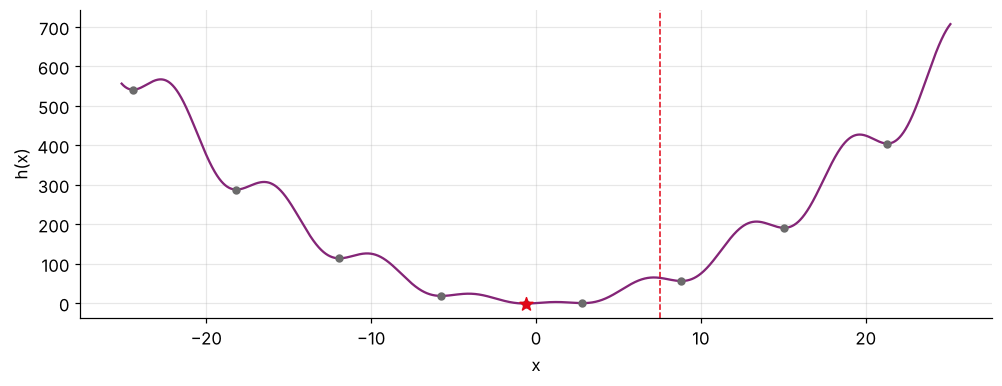

In [5]:
n = np.arange(1, 5001)
y_enonce = -8 * np.pi + 16 * np.pi * (n - 1) / 5000      # formule de l'énoncé
print(f"dernier point de l'énoncé : {y_enonce[-1]:.4f}   8π = {8*np.pi:.4f}")
h_n = h_sujet3(y)
i = np.argmin(h_n)
print(f"min sur la grille : h({y[i]:.4f}) = {h_n[i]:.4f}")

xm_grille, _ = minima_locaux(h_sujet3, a, b)
xm = np.array([brentq(dh_sujet3, x - 0.05, x + 0.05) for x in xm_grille])
hm = h_sujet3(xm)
X_GLOBAL, X_PIEGE = xm[np.argsort(hm)[0]], xm[np.argsort(hm)[1]]
X_LOCAL = brentq(dh_sujet3, 8.0, 9.5)
print(len(xm), "minima locaux ; global :", round(X_GLOBAL, 4), round(hm.min(), 4),
      "; 2e plus bas :", round(X_PIEGE, 4), round(h_sujet3(X_PIEGE), 4),
      "; bassin de 7,5 :", round(X_LOCAL, 4), round(h_sujet3(X_LOCAL), 4))

fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
ax.plot(y, h_n, color=VIOLET); ax.scatter(xm, hm, color=GRIS, s=20, zorder=3)
ax.scatter([X_GLOBAL], [hm.min()], color=ROUGE, marker="*", s=80, zorder=4)
ax.axvline(7.5, color=ROUGE, ls="--", lw=1); ax.set_xlabel("x"); ax.set_ylabel("h(x)")
plt.show()

### 📊 Lecture
- La formule de l'énoncé s'arrête à $25{,}1227$, juste avant $8\pi \approx 25{,}1327$ (voir ⚠️).
- `min` de la grille : $h(-0{,}6385) = -1{,}1304$. Affiné : $x^\star = -0{,}6371$,
  $h(x^\star) = -1{,}1305$. L'écart $0{,}0014$ est plus petit que le pas de grille
  ($16\pi/4999 \approx 0{,}010$) : normal.
- **9 minima locaux**. Le deuxième plus bas, $x = 2{,}8051$ ($h = -0{,}0748$), sera le piège du
  recuit (Q4).
- $x_0 = 7{,}5$ est entre deux sommets ($7{,}14$ et $13{,}37$) : on est dans le bassin du minimum
  local $8{,}8137$, où $h = 56{,}03$, soit 57 unités au-dessus du global.

### ⚠️ Pièges
- **Coquille** : $\frac{n-1}{5000}$ n'atteint pas $8\pi$ ; il faut $\frac{n-1}{4999}$ (= `linspace`).
- **Coquille** : « $h = -h$ » doit se lire $\tilde h = -h$.
- Le `min` de la grille trouve le global **ici** parce qu'on est en dimension 1 ; en dimension
  $d$, il faudrait $5000^d$ points : c'est pour ça qu'on a besoin des algorithmes.
- $h$ n'est **pas** paire : $h(-x) = x^2 - 3x\cos x \ne h(x)$.

### ✋ À toi
1. Vérifie numériquement que $h(x) \ge |x|(|x|-3)$ sur toute la grille `y`.
2. Combien de **maxima** locaux $h$ a-t-elle sur l'intervalle ? (indice : `minima_locaux` appliqué à $-h$)

In [6]:
# 1. print(np.all(h_sujet3(y) >= np.abs(y) * (np.abs(y) - 3)))
# 2. xM, _ = minima_locaux(lambda x: -h_sujet3(x), a, b) ; print(len(xM))

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

1. `True` : la minoration est vraie partout (étapes 6-7 du calcul).
2. ```python
   xM, _ = minima_locaux(lambda x: -h_sujet3(x), a, b)
   print(len(xM), np.round(xM, 3))   # 8 maxima, dont 1,227 et 7,143
   ```
   Un minimum de $-h$ est un maximum de $h$ (Partie 0). Entre deux minima consécutifs, il y a
   toujours un maximum : 9 minima ⇒ 8 maxima intérieurs.

</details>

<details>
<summary><b>🗣️ 30 s — à dire au jury</b></summary>

« $h$ est une parabole à laquelle s'ajoute une oscillation $3x\cos x$ d'amplitude croissante.
Sa dérivée seconde change de signe : elle n'est pas convexe, et j'ai compté 9 minima locaux sur
l'intervalle. Le minimum global est en $-0{,}637$, avec $h = -1{,}13$ ; on peut même prouver
qu'il est dans $]-3, 3[$, car $h(x) \ge |x|(|x|-3) > 0$ dès que $|x| > 3$. Le point de départ
$7{,}5$ est dans la cuvette du minimum local $8{,}81$. J'ai aussi noté que la grille de l'énoncé
n'atteint pas $8\pi$ : il faut diviser par 4999. »

</details>

### 🎤 Jury
Questions 1, 3, 18, 19, 20 de [questions_oral.md](questions_oral.md).
**Piège typique :** « Pourquoi ne pas juste prendre le min de la grille ? » → ça marche en 1D,
pas en grande dimension.

---
## Q2 · Gradient simple

### 🎯 Objectif
*Énoncé :* « Implémenter $x_{n+1} = x_n - \alpha_n h'(x_n)$ avec $\alpha_n = 0{,}025/n$ […] de
l'ordre de 1000 itérations. Visualiser sur le graphe la convergence de la suite $(x_n)$ vers un
minimum local de $h$. »

**Ce qu'on demande vraiment :** partir de $x_0 = 7{,}5$, faire 1000 pas « en descendant », et
montrer sur la courbe où la suite aboutit. Vocabulaire : $\alpha_n$ = **pas** (longueur du
déplacement), $h'$ = **gradient** (en dimension 1, c'est la dérivée).

### 💡 Intuition
**Une bille sur la courbe** : à chaque pas, elle roule un peu dans le sens de la pente. Elle
s'arrête au fond de la cuvette **où elle se trouve**, jamais dans une autre : pour changer de
cuvette, il faudrait remonter. La figure montre les premiers pas (flèches) à partir de 7,5 avec un
pas volontairement **agrandi** ($\times 4$) pour qu'on les voie.

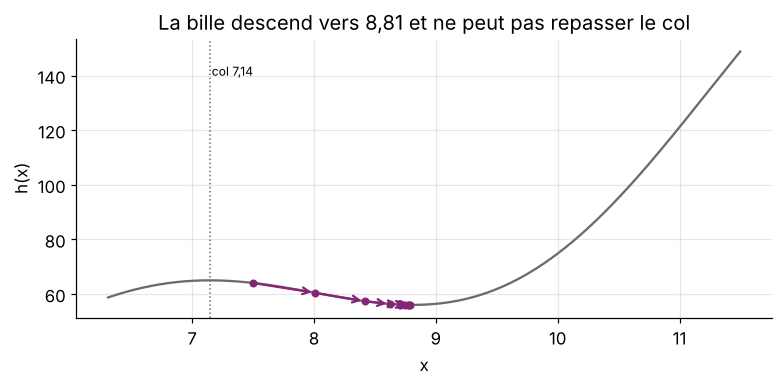

In [7]:
xs = [7.5]
for n_ in range(1, 9):                      # 8 pas, pas agrandi x4 (illustration seulement)
    xs.append(xs[-1] - 4 * pas_sujet3(n_) * dh_sujet3(xs[-1]))
z = (y > 6.3) & (y < 11.5)
fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
ax.plot(y[z], h_sujet3(y[z]), color=GRIS)
for x1, x2 in zip(xs[:-1], xs[1:]):
    ax.annotate("", xy=(x2, h_sujet3(x2)), xytext=(x1, h_sujet3(x1)),
                arrowprops=dict(arrowstyle="->", color=VIOLET, lw=1.5))
ax.scatter(xs, h_sujet3(np.array(xs)), color=VIOLET, s=18, zorder=3)
ax.axvline(7.143, color=GRIS, ls=":", lw=1); ax.text(7.16, 140, "col 7,14", fontsize=8)
ax.set_xlabel("x"); ax.set_ylabel("h(x)")
ax.set_title("La bille descend vers 8,81 et ne peut pas repasser le col")
plt.show()

### 🧮 Calcul

**Pourquoi $h$ diminue.**

| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1 | $h(x + \delta) = h(x) + \delta\,h'(x) + o(\delta)$ | développement de Taylor à l'ordre 1 ($h$ dérivable) |
| 2 | on choisit $\delta = -\alpha h'(x)$ | c'est la règle du gradient |
| 3 | $h(x - \alpha h'(x)) = h(x) - \alpha\,h'(x)^2 + o(\alpha)$ | on remplace $\delta$ |
| 4 | $-\alpha h'(x)^2 < 0$ si $h'(x) \ne 0$ | un carré est positif, $\alpha > 0$ |
| 5 | $h$ baisse si $\alpha$ est assez petit | le $o(\alpha)$ devient négligeable |
| 6 | plus précisément $h(x - \alpha g) \le h(x) - \alpha g^2 (1 - \alpha M/2)$, $g = h'(x)$ | Taylor-Lagrange à l'ordre 2, $M$ = majorant de $h''$ sur le segment |
| 7 | ici $M \approx 20{,}2$ et $\alpha_n \le 0{,}025$ : $\alpha_n M/2 \le 0{,}25 < 1$ | donc $h$ baisse **strictement** à chaque pas |

**Les conditions sur le pas** ($\alpha_n = 0{,}025/n$) :
- $\sum \alpha_n = 0{,}025\sum 1/n = +\infty$ (série harmonique) : sinon le chemin total serait
  borné par $\sup|h'| \cdot \sum\alpha_n$ et on pourrait s'arrêter **avant** le minimum ;
- $\sum \alpha_n^2 = 0{,}025^2 \sum 1/n^2 = 0{,}025^2\,\pi^2/6 < \infty$ : les pas s'éteignent,
  la suite ne peut pas osciller indéfiniment.

**La vitesse.** Notons $\bar x \approx 8{,}814$ le minimum **local** visé (on garde $x^\star$ pour le
minimum global) et $e_n = x_n - \bar x$ l'erreur.

| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1 | $h'(x) \approx h''(\bar x)(x - \bar x)$ | Taylor de $h'$ en $\bar x$, avec $h'(\bar x) = 0$ |
| 2 | $e_{n+1} \approx e_n - \frac{0{,}025}{n} h'(x_n) \approx \left(1 - \frac{c}{n}\right) e_n$, $c = 0{,}025\,h''(\bar x)$ | on soustrait $\bar x$ à la règle du gradient ($\alpha_{n+1} \approx \alpha_n$ pour $n$ grand) |
| 3 | $e_n \approx e_1 \prod_{k<n}(1 - c/k)$ | on itère |
| 4 | $\ln\prod(1 - c/k) \approx -c\sum 1/k \approx -c\ln n$ | $\ln(1-u) \approx -u$ pour $u$ petit ; somme harmonique $\approx \ln n$ |
| 5 | $\lvert e_n\rvert \approx C\,n^{-c}$ | on repasse à l'exponentielle |

$$\boxed{|x_n - \bar x| \approx C\,n^{-c},\qquad c = 0{,}025\,h''(\bar x)\quad (C \text{ constante})}$$

**Contrôle :** en échelle log-log, $\ln|e_n| \approx \ln C - c\ln n$ est une **droite de pente
$-c$** : on va la mesurer.

### 🐍 Code

In [8]:
print(inspect.getsource(pas_sujet3)); print(inspect.getsource(gradient_simple))

def pas_sujet3(n):
    """Pas conseillé alpha_n = 0,025 / n : sum alpha_n = +inf, sum alpha_n² < +inf."""
    return 0.025 / n

def gradient_simple(grad, x0, N, pas=pas_sujet3):
    """x_n = x_{n-1} - alpha_n h'(x_{n-1}), pour n = 1, ..., N.

    (Numérotation qui évite alpha_0 = 0,025/0, non défini.)

    Déterministe : même x0, même trajectoire. Renvoie le tableau (x_0, ..., x_N).
    """
    if N < 1:
        raise ValueError("N doit être >= 1")
    x = np.empty(N + 1)
    x[0] = x0
    for n in range(1, N + 1):
        x[n] = x[n - 1] - pas(n) * grad(x[n - 1])
    return x



- `x = np.empty(N + 1)` : on réserve la place pour $x_0, \dots, x_N$ (toute la trajectoire, pour
  la tracer).
- `for n in range(1, N + 1)` : $n$ va de 1 à $N$ (comme `for n = 1:N`) ; on commence à 1 car
  $\alpha_n = 0{,}025/n$ n'est pas défini en $n = 0$.
- `x[n] = x[n - 1] - pas(n) * grad(x[n - 1])` : la formule (1) de l'énoncé, numérotée
  $x_n = x_{n-1} - \alpha_n h'(x_{n-1})$ pour que le premier pas utilise $\alpha_1$ (l'énoncé, pris à la
  lettre, demanderait $\alpha_0 = 0{,}025/0$ : coquille).
- `grad` est passé en argument : la même fonction marche pour n'importe quelle $h$.

h'(7,5) = -5.065  ->  x_1 = 7.6266
x_N = 8.6606, h(x_N) = 56.2483 ; h décroît à chaque pas : True
écarts n = 10^3, 10^4, 10^5 : [0.1531 0.0509 0.0162]
pente log-log : -0.494   théorie -c : -0.505


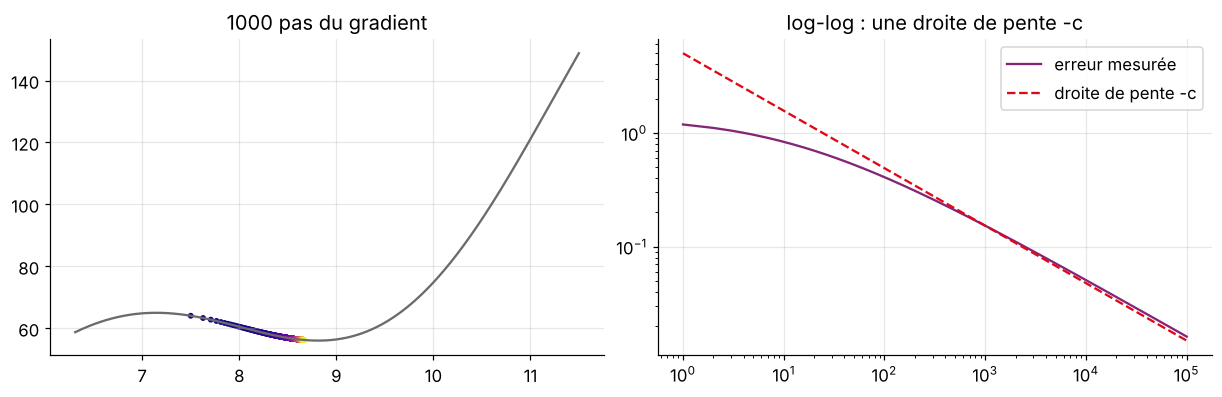

In [9]:
N = 1000
xg = gradient_simple(dh_sujet3, 7.5, N)
print(f"h'(7,5) = {dh_sujet3(7.5):.3f}  ->  x_1 = {xg[1]:.4f}")
print(f"x_N = {xg[-1]:.4f}, h(x_N) = {h_sujet3(xg[-1]):.4f} ; h décroît à chaque pas : {bool(np.all(np.diff(h_sujet3(xg)) <= 0))}")
xg_long = gradient_simple(dh_sujet3, 7.5, 100_000)
erreur = np.abs(xg_long - X_LOCAL)
c_theo = 0.025 * (2 - 6 * np.sin(X_LOCAL) - 3 * X_LOCAL * np.cos(X_LOCAL))
k = np.arange(1000, 100_001)
pente = np.polyfit(np.log(k), np.log(erreur[k]), 1)[0]
print("écarts n = 10^3, 10^4, 10^5 :", np.round(erreur[[1000, 10_000, 100_000]], 4))
print(f"pente log-log : {pente:.3f}   théorie -c : {-c_theo:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
z = (y > 6.3) & (y < 11.5)
ax1.plot(y[z], h_n[z], color=GRIS); ax1.scatter(xg, h_sujet3(xg), c=np.arange(N + 1), cmap="plasma", s=8)
ax1.set_title("1000 pas du gradient")
nn = np.arange(1, 100_001)
ax2.loglog(nn, erreur[1:], color=VIOLET, label="erreur mesurée")
ax2.loglog(nn, erreur[1000] * (nn / 1000) ** (-c_theo), color=ROUGE, ls="--", label="droite de pente -c")
ax2.legend(); ax2.set_title("log-log : une droite de pente -c")
plt.show()

### 📊 Lecture
- $h'(7{,}5) = -5{,}065 < 0$ : la pente descend vers la droite, donc
  $x_1 = 7{,}5 + 0{,}025 \times 5{,}065 = 7{,}6266$. La bille part à droite.
- $h$ décroît à **chaque** pas (vérifié), et $x_{1000} = 8{,}6606$, $h = 56{,}25$ : la suite
  va vers le minimum **local** $8{,}8137$ ($h = 56{,}03$), jamais vers le global ($-1{,}13$).
- Il reste un écart de $0{,}153$ après 1000 pas, $0{,}051$ après $10^4$, $0{,}016$ après $10^5$ :
  divisé par $\approx 3{,}1 \approx \sqrt{10}$ à chaque fois qu'on multiplie $n$ par 10.
- Pente log-log mesurée $-0{,}494$, théorie $-c = -0{,}025 \times 20{,}2 = -0{,}505$ : accord à
  $0{,}01$ près. L'erreur décroît en $1/\sqrt n$ : **convergence lente**.

### ⚠️ Pièges
- Signe : c'est **moins** $\alpha_n h'$ (avec +, on monterait).
- « Le gradient converge vers le minimum » : vers un minimum **local**, celui du bassin de $x_0$.
- « 1000 itérations suffisent » : pour **voir** la convergence, pas pour l'atteindre à
  $10^{-3}$ près.
- **Notation** : le $\alpha_n$ du gradient n'a rien à voir avec le $\alpha = 0{,}99$ du recuit.

### ✋ À toi
1. Lance le gradient depuis $x_0 = 2$ puis $x_0 = 0$. Où arrive-t-il ? Pourquoi ?
2. Remplace le pas par un pas **constant** $\alpha = 0{,}02$ (`pas=lambda n: 0.02`) depuis 7,5 :
   l'écart après 1000 pas est-il plus petit ?

In [10]:
# 1. print(gradient_simple(dh_sujet3, 2.0, 1000)[-1], gradient_simple(dh_sujet3, 0.0, 1000)[-1])
# 2. xc = gradient_simple(dh_sujet3, 7.5, 1000, pas=lambda n: 0.02) ; print(abs(xc[-1] - X_LOCAL))

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

1. Depuis 2 : $x_{1000} \approx 2{,}47$, en route vers $2{,}805$ (le piège : $h'(2) \approx -2{,}7 < 0$,
   on va à droite, dans la cuvette de 2,8). Depuis 0 : $x_{1000} \approx -0{,}42$, en route vers
   $-0{,}637$ (le global : $h'(0) = 3 > 0$, on va à gauche, et 0 est à gauche du col 1,227). Le
   minimum atteint dépend **entièrement** de $x_0$ (et 1000 pas ne suffisent pas à y arriver).
2. Avec $\alpha$ constant, $e_{n+1} \approx (1 - \alpha h'')e_n = (1 - 0{,}02 \times 20{,}2)e_n
   \approx 0{,}6\,e_n$ : convergence **géométrique**, l'écart est quasi nul (bien plus petit que
   0,153). Attention : il faut $\alpha < 2/h''(x^\star) \approx 0{,}1$, sinon la suite oscille et diverge.

</details>

<details>
<summary><b>🗣️ 30 s — à dire au jury</b></summary>

« Le gradient fait $x_{n+1} = x_n - \alpha_n h'(x_n)$ : par Taylor, $h$ baisse d'environ
$\alpha_n h'(x_n)^2$ à chaque pas. Les conditions $\sum\alpha_n = \infty$ et $\sum\alpha_n^2 < \infty$
assurent qu'on va assez loin sans osciller. Parti de 7,5, il descend vers le minimum local 8,81
et ne peut pas remonter le col en 7,14 : il n'atteint jamais le global. Il est lent : près du
minimum l'erreur décroît en $n^{-c}$ avec $c = 0{,}025\,h'' \approx 0{,}5$ ; j'ai mesuré une
pente log-log de $-0{,}494$. »

</details>

### 🎤 Jury
Questions 2, 4, 5, 6, 7, 8. **Piège typique :** « Votre gradient a-t-il convergé ? » → oui en
tendance, mais il reste 0,153 d'écart à $n = 1000$ ; donnez la vitesse $n^{-1/2}$.

---
## Q3 · Recuit simulé

### 🎯 Objectif
*Énoncé :* « Distribution instrumentale $g_n$ uniforme sur $[x_n - \frac\pi2, x_n + \frac\pi2]$ ;
températures $T_n = T_0\alpha^n$, $T_0 = 500$, $\alpha = 0{,}99$. Visualiser la convergence de
$x_n$ vers un minimum cette fois-ci global de $h$. »

**Ce qu'on demande vraiment :** même départ 7,5, mais à chaque pas on **propose** un point $z$ au
hasard près de $x_n$ et on décide de s'y déplacer ou non ; on accepte toujours une descente, et
**parfois** une montée. Vocabulaire : *distribution instrumentale* = la loi qui sert à proposer
$z$ ; *température* $T_n$ = le réglage qui dit à quel point on tolère les montées ; *recuit* vient
de la métallurgie (on refroidit lentement un métal pour qu'il atteigne un état d'énergie minimale).

### 💡 Intuition
**Un randonneur qui se fatigue** : au début (température haute) il accepte volontiers de grimper,
donc il visite toute la région ; peu à peu il refuse les montées et finit par ne plus faire que
descendre. S'il a eu le temps d'atteindre la grande vallée avant d'être « gelé », il y reste.

La figure montre la probabilité d'accepter une montée de $\Delta h$ pour quelques températures.

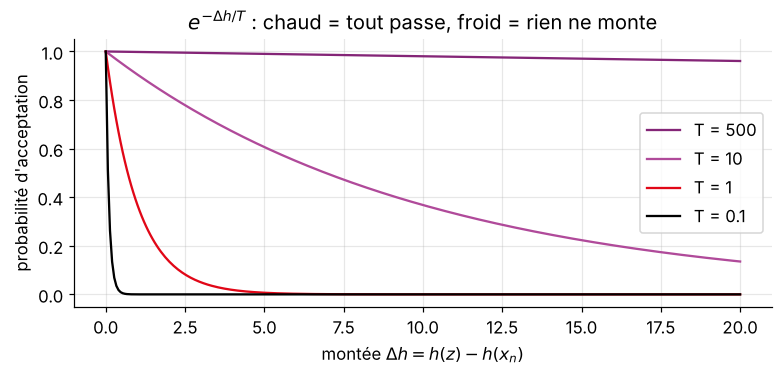

In [11]:
d = np.linspace(0, 20, 300)
fig, ax = plt.subplots(figsize=(7, 3.3), layout="constrained")
for T, coul in ((500, VIOLET), (10, "#b04a9a"), (1, ROUGE), (0.1, "k")):
    ax.plot(d, np.exp(-d / T), color=coul, label=f"T = {T}")
ax.set_xlabel(r"montée $\Delta h = h(z) - h(x_n)$"); ax.set_ylabel("probabilité d'acceptation")
ax.legend(); ax.set_title(r"$e^{-\Delta h / T}$ : chaud = tout passe, froid = rien ne monte")
plt.show()

### 🧮 Calcul

**La règle d'acceptation.** $p_n = \min(1, e^{-\Delta h_n/T_n})$ avec $\Delta h_n = h(z) - h(x_n)$.

| Cas | Valeur de $p_n$ | Pourquoi |
|---|---|---|
| $\Delta h_n \le 0$ (descente) | 1 | $e^{-\Delta/T} \ge 1$, le min vaut 1 |
| $\Delta h_n > 0$, $T$ grand | $\approx 1$ | $\Delta/T \approx 0$ |
| $\Delta h_n > 0$, $T \to 0$ | $\to 0$ | $e^{-\Delta/T} \to 0$ |

**Ordres de grandeur.** $T_n = 1 \iff 0{,}99^n = 1/500 \iff n = \ln 500/\ln(1/0{,}99) \approx 618$ ;
$T_{1000} = 500 \times 0{,}99^{1000} \approx 0{,}022$.

**Pourquoi ça vise le global (équilibre détaillé).** Fixons $T$. Soit $\mu_T(x) = e^{-h(x)/T}/Z$
($Z$ = constante qui fait que l'intégrale vaut 1 : c'est la **loi de Boltzmann**). La densité de
proposition est $g(y\mid x) = 1/\pi$ si $|y - x| \le \pi/2$ : elle est **symétrique**,
$g(y\mid x) = g(x\mid y)$.

| Étape | Calcul | Pourquoi on a le droit |
|---|---|---|
| 1 | flux $x \to y$ : $\mu_T(x)\,g(y\mid x)\,\min\big(1, \frac{\mu_T(y)}{\mu_T(x)}\big)$ | $e^{-(h(y)-h(x))/T} = \mu_T(y)/\mu_T(x)$ (les $Z$ se simplifient) |
| 2 | $= g(y\mid x)\,\min(\mu_T(x), \mu_T(y))$ | on rentre $\mu_T(x) > 0$ dans le min |
| 3 | $= g(x\mid y)\,\min(\mu_T(y), \mu_T(x))$ = flux $y \to x$ | symétrie de $g$ et du min |
| 4 | $\mu_T$ est stationnaire | équilibre détaillé (flux égaux dans les deux sens) ⇒ stationnarité |

Et la loi stationnaire se concentre sur le minimum global quand $T \to 0$ :
$$\boxed{\frac{\mu_T(x)}{\mu_T(x^\star)} = e^{-(h(x) - h(x^\star))/T} \xrightarrow[T\to 0]{} 0 \quad\text{si } h(x) > h(x^\star)}$$

**Contrôle :** à $T = 500$, $\mu_T$ est presque uniforme (tout est visité) ; à $T = 0{,}02$, elle
est concentrée autour de $x^\star$.

### 🐍 Code

In [12]:
print(inspect.getsource(recuit_simule))

def recuit_simule(f, x0, N, rng, T0=500.0, alpha=0.99, demi_largeur=np.pi / 2, bornes=None):
    """Recuit simulé, températures T_n = T0 * alpha^n.

    À l'itération n : z ~ U[x_n - demi_largeur, x_n + demi_largeur] (loi g_n) ;
    si f(z) <= f(x_n) on accepte ; sinon on accepte avec la probabilité
    exp(-(f(z) - f(x_n)) / T_n) ; en cas de refus, x_{n+1} = x_n.
    Si ``bornes`` = (a, b) est donné, un z hors de [a, b] est refusé : on
    minimise sur l'intervalle, pas sur R.

    Renvoie (x, acceptes) : la trajectoire (x_0, ..., x_N) et un booléen par
    itération (True si z a été accepté).
    """
    if T0 <= 0 or not 0 < alpha < 1:
        raise ValueError("il faut T0 > 0 et 0 < alpha < 1")
    if N < 1:
        raise ValueError("N doit être >= 1")
    if bornes is not None and not bornes[0] <= x0 <= bornes[1]:
        raise ValueError("x0 doit être dans les bornes")
    x = np.empty(N + 1)
    x[0] = x0
    fx = f(x0)
    acceptes = np.zeros(N, dtype=bool)
    for n in range(1,

- `T = T0 * alpha**n` : la température $T_n$.
- `z = x[n - 1] + rng.uniform(-demi_largeur, demi_largeur)` : $z \sim \mathcal U[x_n - \pi/2, x_n + \pi/2]$
  (Matlab : `x - pi/2 + pi*rand`).
- `u = rng.random()` : on tire $U$ **à chaque itération**, même si on n'en a pas besoin, pour que le
  nombre de tirages soit toujours le même (reproductibilité).
- `dedans = ...` : un $z$ hors de $[-8\pi, 8\pi]$ est refusé (on minimise sur l'intervalle).
- `if delta <= 0 or u < np.exp(-delta / T)` : descente ⇒ on accepte ; montée ⇒ on accepte avec
  probabilité $e^{-\Delta/T}$ (Partie 0.4). Grâce au `or`, l'exponentielle n'est calculée que pour les
  montées.
- Sinon `x[n] = x[n - 1]` : on reste sur place (ça compte quand même comme une itération).
- `acceptes` : garde la trace des acceptations, pour mesurer le taux.

x_N = -0.6503, h(x_N) = -1.1298 ; meilleur visité : -0.6334
zone explorée : [-2.97 ; 15.34]
taux d'acceptation par blocs de 100 : [0.99 0.92 0.93 0.53 0.7  0.57 0.39 0.28 0.12 0.09]
dernière itération loin (> 0,5) du global : n = 702


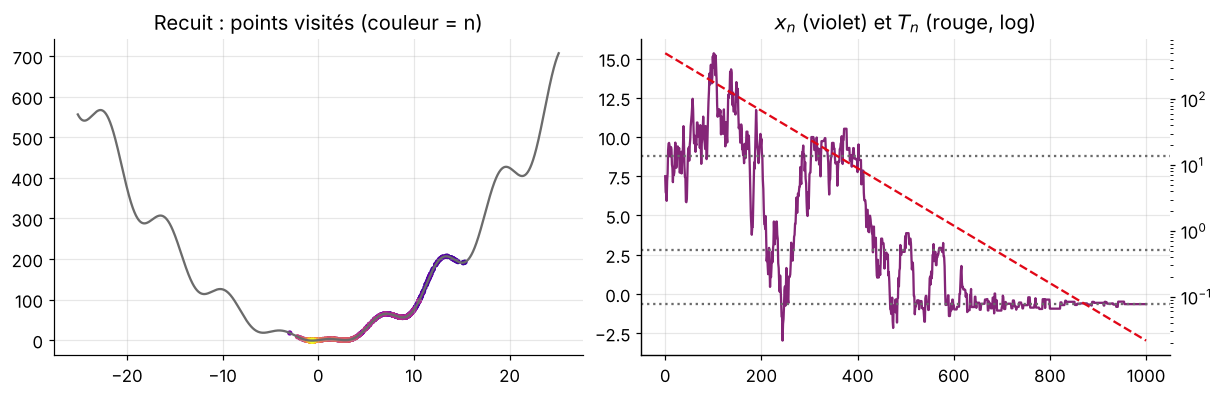

In [13]:
T0, ALPHA = 500.0, 0.99
xr, acc = recuit_simule(h_sujet3, 7.5, N, rng, T0=T0, alpha=ALPHA, bornes=BORNES_SUJET3)  # 1er usage de rng
Tn = T0 * ALPHA ** np.arange(N + 1)
print(f"x_N = {xr[-1]:.4f}, h(x_N) = {h_sujet3(xr[-1]):.4f} ; meilleur visité : {xr[np.argmin(h_sujet3(xr))]:.4f}")
print(f"zone explorée : [{xr.min():.2f} ; {xr.max():.2f}]")
print("taux d'acceptation par blocs de 100 :", np.round(acc.reshape(10, 100).mean(axis=1), 2))
print("dernière itération loin (> 0,5) du global : n =", np.max(np.nonzero(np.abs(xr - X_GLOBAL) > 0.5)[0]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
ax1.plot(y, h_n, color=GRIS); ax1.scatter(xr, h_sujet3(xr), c=np.arange(N + 1), cmap="plasma", s=6)
ax1.set_title("Recuit : points visités (couleur = n)")
ax2.plot(xr, color=VIOLET)
for xx in (X_GLOBAL, X_PIEGE, X_LOCAL):
    ax2.axhline(xx, color=GRIS, ls=":")
ax3 = ax2.twinx(); ax3.semilogy(Tn, color=ROUGE, ls="--"); ax3.grid(False)
ax2.set_title(r"$x_n$ (violet) et $T_n$ (rouge, log)")
plt.show()

### 📊 Lecture
- Au début, $T$ est énorme : **99 %** des propositions sont acceptées sur les 100 premières
  itérations, la suite monte jusqu'à $15{,}3$ et descend jusqu'à $-3$ : elle **explore** et sort
  du bassin de 8,81.
- Vers $n \approx 618$, $T$ passe sous 1 : les montées deviennent rares. Dernière sortie du
  voisinage $\pm 0{,}5$ du global à $n = 702$ ; taux d'acceptation final $0{,}09$.
- Résultat : $x_N = -0{,}6503$, $h(x_N) = -1{,}1298$ contre $-1{,}1305$ : **minimum global**
  trouvé (meilleur point visité $-0{,}6334$). Précision moyenne, car on propose toujours des sauts
  de largeur $\pm\pi/2$, même à froid.
- ⚠️ Ce n'est **qu'un** lancer : la Q4 dit ce qu'il se passe en moyenne.

### ⚠️ Pièges
- La largeur totale de $g_n$ est $\pi$ (de $-\pi/2$ à $+\pi/2$), pas $\pi/2$.
- Refuser $z$ ne veut pas dire « ne rien faire » : $x_{n+1} = x_n$ compte comme une itération.
- « Ce choix garantit la convergence presque sûre » (énoncé) : **faux**, voir Q4.
- Comparer $U$ à $p$, pas $p$ à $0{,}5$.

### ✋ À toi
1. Calcule à la main la probabilité d'accepter une montée $\Delta h = 10$ à $n = 0$ ($T = 500$) et à
   $n = 600$ ($T \approx 1{,}2$).
2. Relance le recuit avec `rng_exo` (pour ne pas décaler `rng`) et une largeur $\pm 0{,}5$
   (`demi_largeur=0.5`). Où finit-il ?

In [14]:
# 1. print(np.exp(-10 / 500), np.exp(-10 / (500 * 0.99**600)))
# 2. xe, _ = recuit_simule(h_sujet3, 7.5, 1000, rng_exo, demi_largeur=0.5, bornes=BORNES_SUJET3) ; print(xe[-1])

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

1. $e^{-10/500} = e^{-0{,}02} \approx 0{,}98$ : presque toujours accepté. $T_{600} = 500 \times
   0{,}99^{600} \approx 1{,}20$, $e^{-10/1{,}2} \approx 2{,}4 \times 10^{-4}$ : quasi jamais.
2. Avec des pas plus petits, il faut beaucoup plus d'itérations pour traverser les cuvettes : le
   résultat dépend fortement du tirage. Sur 200 lancers (graines 0 à 199), j'obtiens environ 38 %
   au global, 34 % en 2,8 et 25 % encore en 8,81, contre 74 % au global avec $\pm\pi/2$. La largeur de
   $g_n$ est un vrai réglage : trop petite, on n'explore pas ; trop grande, on est imprécis à la fin.

</details>

<details>
<summary><b>🗣️ 30 s — à dire au jury</b></summary>

« À chaque itération je propose $z$ uniforme dans $[x_n - \pi/2, x_n + \pi/2]$. Si $h$ baisse,
j'accepte ; sinon j'accepte avec probabilité $e^{-\Delta h/T_n}$, en tirant $U$ uniforme et en
acceptant si $U$ est plus petit. Quand $T$ est grand presque tout passe, donc on explore ; quand
$T$ baisse on ne fait plus que descendre. La justification : à $T$ fixé, la chaîne a pour loi
stationnaire $e^{-h/T}$ par équilibre détaillé, et cette loi se concentre sur le minimum global
quand $T \to 0$. Sur mon lancer, parti de 7,5, je finis en $-0{,}650$, dans le minimum global. »

</details>

### 🎤 Jury
Questions 9, 10, 11, 12, 21. **Piège typique :** « Pourquoi accepter une montée ? » → pour
sortir des cuvettes ; sans ça, c'est un gradient aléatoire, piégé comme le gradient.

---
## Q4 · Comparer les deux méthodes

### 🎯 Objectif
*Énoncé :* « Commenter. Comparer les deux méthodes en termes de garanties de convergence, de
vitesses de convergence, de complexité de compréhension, de complexité de mise en œuvre… »

**Ce qu'on demande vraiment :** un avis argumenté, **chiffré**. Pour le recuit, un seul lancer ne
suffit pas : on le relance 1000 fois et on mesure la proportion de succès.

### 💡 Intuition
Le recuit « gèle » quand $T$ devient petit. À ce moment, la proportion de lancers dans chaque
cuvette ressemble à la loi de Boltzmann $\mu_T$ : si deux cuvettes ont presque la même profondeur,
une part non négligeable des lancers gèle dans la **mauvaise**. La figure montre $\mu_T$ pour
trois températures : à $T = 1$, le creux en 2,8 a encore beaucoup de poids.

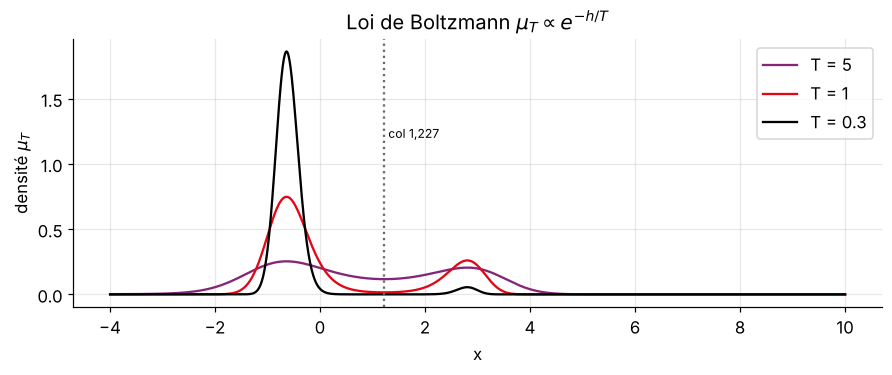

In [15]:
z = (y > -4) & (y < 10)
fig, ax = plt.subplots(figsize=(8, 3.3), layout="constrained")
for T, coul in ((5, VIOLET), (1, ROUGE), (0.3, "k")):
    w = np.exp(-(h_n[z] - h_n.min()) / T)
    ax.plot(y[z], w / np.trapezoid(w, y[z]), color=coul, label=f"T = {T}")
ax.axvline(1.227, color=GRIS, ls=":"); ax.text(1.3, 1.2, "col 1,227", fontsize=8)
ax.set_xlabel("x"); ax.set_ylabel(r"densité $\mu_T$"); ax.legend()
ax.set_title(r"Loi de Boltzmann $\mu_T \propto e^{-h/T}$")
plt.show()

### 🧮 Calcul

**Évaluer un algorithme aléatoire.** $R$ lancers indépendants, $k$ succès : $\hat p = k/R$, erreur-type
$\sqrt{\hat p(1-\hat p)/R}$, IC à 95 % : $\hat p \pm 1{,}96\times$erreur-type (TCL, $R$ grand).

**Comparer deux proportions** : écart en erreurs-types
$\dfrac{\hat p_2 - \hat p_1}{\sqrt{\text{e.t.}_1^2 + \text{e.t.}_2^2}}$ (lancers indépendants, les variances
s'ajoutent). Repères : $< 2$ courant, $\approx 2$ limite à 95 %, $> 3$ suspect.

**La garantie théorique (Hajek, 1988, espace d'états fini).** Profondeur d'un minimum local =
hauteur à remonter pour en sortir vers un point plus bas. Avec $T_n = c/\ln n$,
$P(x_n \in \arg\min h) \to 1$ **si et seulement si** $c \ge d^\star$ (profondeur du minimum local non
global le plus profond). C'est une convergence **en probabilité**, pas presque sûre. Profondeurs à
petits pas :

| minimum local | $h$ | col | profondeur |
|---|---|---|---|
| 2,805 | $-0{,}075$ | 1,227 ($h = 2{,}746$) | 2,82 |
| 8,814 | 56,03 | 7,143 ($h = 65{,}01$) | 8,98 |
| $-24{,}44$ | 540,9 | $-22{,}76$ ($h = 567{,}1$) | 26,2 |

Avec des sauts de $\pm\pi/2$, la chaîne enjambe une partie des cols : profondeurs effectives
$\approx 12{,}3$ pour $-24{,}44$ et $\approx 1{,}5$ pour $2{,}805$ ([demonstrations.md](demonstrations.md#q3)).
Il faudrait donc $c \gtrsim 12$, soit $T_{1000} \gtrsim 1{,}8$ (contre $0{,}022$) : refroidissement
**beaucoup trop lent** en pratique.

**Pourquoi le géométrique gèle (Borel-Cantelli).** Franchir un col de hauteur $d$ à l'étape $n$ a une
probabilité de l'ordre de $e^{-d/T_n}$ au plus. Avec $T_n = T_0\alpha^n$, $\sum_n e^{-d/T_n} < \infty$
(les termes décroissent doublement exponentiellement). Lemme de Borel-Cantelli : si la somme des
probabilités d'une suite d'événements est finie, presque sûrement seul un nombre fini d'entre eux se
produit. Donc la chaîne finit par **geler** dans un bassin aléatoire, et l'affirmation « ce choix
garantit la convergence presque sûre » est **fausse**.

**Contrôle :** les tableaux de profondeurs se lisent sur la figure de Q1 (sommet du col moins fond
de cuvette).

### 🐍 Code
On relance `recuit_simule` 1000 fois **avec le même `rng`** (il continue, donc chaque lancer a ses
propres tirages : ils sont indépendants), puis une variante refroidie plus lentement.

global : 0.738 ± 0.027 ; piège 2,805 : 0.259 ; ailleurs : 0.003


alpha = 0,995, N = 2000 : 0.770 ± 0.041 ; écart : 1.27 erreurs-types
échec avec 2 lancers indépendants : 0.069


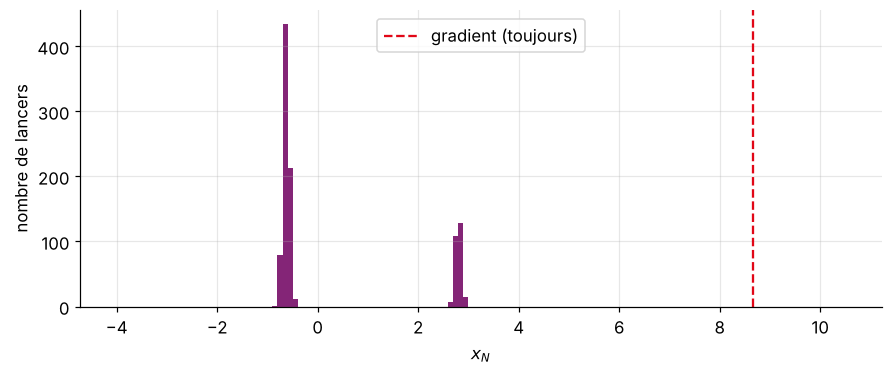

In [16]:
R = 1000
lancers = [recuit_simule(h_sujet3, 7.5, N, rng, T0=T0, alpha=ALPHA, bornes=BORNES_SUJET3) for _ in range(R)]
fins = np.array([x[-1] for x, _ in lancers])

def proportion(masque):
    p = masque.mean(); return p, np.sqrt(p * (1 - p) / len(masque))

p_glob, et_glob = proportion(np.abs(fins - X_GLOBAL) < 0.5)
p_piege, et_piege = proportion(np.abs(fins - X_PIEGE) < 0.5)
print(f"global : {p_glob:.3f} ± {1.96*et_glob:.3f} ; piège 2,805 : {p_piege:.3f} ; ailleurs : {1 - p_glob - p_piege:.3f}")

fins_lent = np.array([recuit_simule(h_sujet3, 7.5, 2000, rng, T0=T0, alpha=0.995, bornes=BORNES_SUJET3)[0][-1]
                      for _ in range(400)])
p_lent, et_lent = proportion(np.abs(fins_lent - X_GLOBAL) < 0.5)
print(f"alpha = 0,995, N = 2000 : {p_lent:.3f} ± {1.96*et_lent:.3f} ; écart : {(p_lent - p_glob)/np.hypot(et_lent, et_glob):.2f} erreurs-types")
print(f"échec avec 2 lancers indépendants : {(1 - p_glob)**2:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.3), layout="constrained")
ax.hist(fins, bins=np.linspace(-4, 10.5, 146), color=VIOLET)
ax.axvline(xg[-1], color=ROUGE, ls="--", label="gradient (toujours)")
ax.set_xlabel(r"$x_N$"); ax.set_ylabel("nombre de lancers"); ax.legend()
plt.show()

### 📊 Lecture
- **Gradient** : déterministe, il finit **toujours** en $8{,}66$ : 0 succès.
- **Recuit** : minimum global dans **73,8 % ± 2,7 %** des 1000 lancers ; piégé en $2{,}805$ dans
  **25,9 %** des cas ; ailleurs 0,3 %. Comme la chaîne gèle, ce 25,9 % est la proportion
  **limite** : la « convergence presque sûre » de l'énoncé est fausse.
- L'intuition Boltzmann colle : à $T = 1$ (là où la chaîne gèle, $n \approx 618$), la masse de $\mu_T$
  dans le bassin de 2,805 vaut $\approx 25$ % (intégration numérique, [demonstrations.md](demonstrations.md#q3)).
- **Refroidir plus lentement** ($\alpha = 0{,}995$, $N = 2000$) : 77,0 % ± 4,1 %, écart de
  **1,27 erreur-type** : pas significatif. Ralentir un refroidissement géométrique ne règle pas
  le problème.
- **Astuce** : 2 lancers indépendants, on garde le meilleur : échec $0{,}262^2 \approx 6{,}9$ %.

| critère | gradient | recuit |
|---|---|---|
| garantie | minimum local (global garanti si $h$ convexe, ou si $x_0$ est dans le bassin du global) | global en probabilité si $T_n = c/\ln n$, $c \ge d^\star$ ; aucune ici (74 %) |
| vitesse | $n^{-0{,}5}$ ici, géométrique à pas constant | bon bassin vers $n \approx 700$, précision grossière |
| coût | 1 calcul de $h'$ par pas, 1 lancer suffit | 1 calcul de $h$ + 2 tirages par pas, plusieurs lancers |
| compréhension | descente de pente | chaîne de Markov, Boltzmann, refroidissement |
| mise en œuvre | 1 paramètre, il faut $h'$ | 3 réglages, pas besoin de $h'$ |

### ⚠️ Pièges
- Conclure sur **un** lancer du recuit.
- Dire « 77 % > 74 %, donc refroidir lentement est mieux » : l'écart (1,27 e.-t.) n'est pas
  significatif.
- Croire que le recuit est « meilleur » en tout : il est plus lent, imprécis à la fin, et demande
  des réglages. Il est meilleur **pour échapper aux minima locaux**.

### ✋ À toi
Avec `rng_exo`, lance **50** recuits avec $T_0 = 5$ au lieu de 500. Le taux de succès change-t-il ?
Pourquoi ?

In [17]:
# f = np.array([recuit_simule(h_sujet3, 7.5, 1000, rng_exo, T0=5, bornes=BORNES_SUJET3)[0][-1] for _ in range(50)])
# print(np.mean(np.abs(f - X_GLOBAL) < 0.5))

<details>
<summary><b>Corrigé (essaie d'abord !)</b></summary>

```python
f = np.array([recuit_simule(h_sujet3, 7.5, 1000, rng_exo, T0=5, bornes=BORNES_SUJET3)[0][-1] for _ in range(50)])
print(np.mean(np.abs(f - X_GLOBAL) < 0.5))
```
À $T_0 = 5$, il faut remonter de $8{,}98$ pour sortir de la cuvette de 8,81 : probabilité
$\approx e^{-9/5} \approx 0{,}17$ par tentative au tout début, et $T$ baisse vite. Une partie des lancers
reste en 8,81 (≈ 17 % sur 300 lancers dans mon essai, contre quasiment 0 avec $T_0 = 500$) et le
taux de succès baisse (≈ 58 % au lieu de 74 %). C'est pourquoi $T_0$ doit être **grand devant la hauteur
des cols** à franchir (500 ≫ 9) : c'est le « taux d'acceptation élevé lors des premières
itérations » de l'énoncé. (Avec 50 lancers seulement, l'erreur-type est d'environ 0,07.)

</details>

<details>
<summary><b>🗣️ 30 s — à dire au jury</b></summary>

« Le gradient est simple, déterministe et converge, mais vers le minimum local de son bassin, et
lentement, en $n^{-1/2}$ ici. Le recuit n'a besoin que de $h$ et peut sortir des cuvettes, mais il
est aléatoire : je l'ai donc évalué sur 1000 lancers. Il trouve le global dans 73,8 % ± 2,7 % des
cas et reste piégé en 2,805 sinon. La garantie théorique demande un refroidissement en $c/\ln n$ ;
avec le refroidissement géométrique de l'énoncé, il n'y a pas de garantie, et le ralentir ne change
pas significativement le résultat. En pratique : recuit pour explorer, gradient pour affiner, ou
plusieurs lancers. »

</details>

### 🎤 Jury
Questions 13, 14, 15, 16, 17. **Piège typique :** « L'énoncé dit que la convergence est garantie,
vous dites le contraire ? » → oui, chiffres et théorème de Hajek à l'appui, calmement.

---
## Récap

```
              h = x² + 3x cos x   (non convexe, 9 minima locaux, global -0,637 ∈ ]-3,3[)
                               │
          ┌────────────────────┴─────────────────────┐
     GRADIENT (déterministe)                   RECUIT (stochastique)
   x ← x − (0,025/n) h'(x)              z ~ U[x ± π/2], accepte si U < e^{-Δh/T}
   Taylor : h baisse de α h'²            T grand : explore ; T petit : descend
   piégé dans le bassin de x0            loi stationnaire π_T ∝ e^{-h/T} → global
   8,66 → 8,81, erreur en n^-0,5         73,8 % ± 2,7 % de succès, 25,9 % en 2,805
          └────────────────────┬─────────────────────┘
       garanties : local (gradient) / global en probabilité si T_n = c/ln n (Hajek)
       en pratique : recuit pour explorer + gradient pour affiner, ou plusieurs lancers
```

### Les 5 questions les plus probables

<details>
<summary><b>Pourquoi le gradient ne trouve-t-il pas le minimum global ?</b></summary>

Il ne fait que descendre ; parti de 7,5 (bassin de 8,81, entre les cols 7,14 et 13,37), il faudrait remonter le col pour changer de cuvette. Il finit en 8,66 après 1000 pas, vers 8,81.

</details>

<details>
<summary><b>Pourquoi accepter des montées dans le recuit, et avec quelle probabilité ?</b></summary>

Pour sortir des cuvettes. Probabilité $e^{-\Delta h/T_n}$ : proche de 1 quand $T$ est grand (exploration), proche de 0 quand $T$ est petit (descente). En pratique : accepter si $U < e^{-\Delta h/T_n}$.

</details>

<details>
<summary><b>Pourquoi le recuit va-t-il vers le minimum global ?</b></summary>

À $T$ fixé, équilibre détaillé avec proposition symétrique ⇒ loi stationnaire $\mu_T \propto e^{-h/T}$, qui se concentre sur les minima globaux quand $T \to 0$.

</details>

<details>
<summary><b>Le recuit converge-t-il toujours ?</b></summary>

Non : 73,8 % ± 2,7 % sur 1000 lancers, 25,9 % piégés en 2,805. Avec $T_n = T_0\alpha^n$ la chaîne gèle (Borel-Cantelli). La garantie de Hajek (en probabilité) demande $T_n = c/\ln n$ avec $c \ge d^\star$ ($\approx 12$ à $26$ ici).

</details>

<details>
<summary><b>Quelle est la vitesse du gradient ?</b></summary>

$|x_n - x^\star| \approx C n^{-c}$, $c = 0{,}025\,h''(x^\star) \approx 0{,}505$ ; pente log-log mesurée $-0{,}494$. Lent ; un pas constant donnerait une convergence géométrique.

</details>

Notebook de rendu : [s3_1_recuit_simule.ipynb](s3_1_recuit_simule.ipynb) · démonstrations :
[demonstrations.md](demonstrations.md) · fiche : [fiche_revision.md](fiche_revision.md).